# Wallet 0xbe90db Sell Volume

This notebook loads `wallet_0xbe90db_transfer_history.csv` and charts the SUI that leaves the wallet when funds are sent to known sell-side counterparties.

Sell counterparties:
- `0xbe9e8a62a74d1246924e10c46b3de0a22ec20998f66d1562c615d3ee846e922e`
- `0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0afa02a34591fd67415e7`
- `0x56f173b16adc96d0a8ac7e3f21e05c3a6621726ab8020140867340198b86e75c`
- `0x7f3b918653aacd4289b7e471aea588b34d497df0e1540c2d22eadacccd3239e4`


In [137]:
from __future__ import annotations

from pathlib import Path
from typing import Iterable

import matplotlib.pyplot as plt
import pandas as pd  # type: ignore

pd.set_option('display.float_format', lambda x: f"{x:,.2f}")


In [138]:
DATA_PATH = Path('/Users/kevincai/Library/Mobile Documents/com~apple~CloudDocs/Career/Interviews/scimitar_capital/sui_insiders/data/diagnostics/wallet_0xbe90db_transfer_history.csv')
SALE_COUNTERPARTIES = {
    '0xbe9e8a62a74d1246924e10c46b3de0a22ec20998f66d1562c615d3ee846e922e',
    '0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0afa02a34591fd67415e7',
    '0x56f173b16adc96d0a8ac7e3f21e05c3a6621726ab8020140867340198b86e75c',
    '0x7f3b918653aacd4289b7e471aea588b34d497df0e1540c2d22eadacccd3239e4',
}


In [ ]:
DATE_START = pd.Timestamp('2024-05-01', tz='UTC')
DATE_END = pd.Timestamp('2024-10-31 23:59:59', tz='UTC')
EXPORT_HISTORY = True
HISTORY_OUTPUT_PATH = DATA_PATH.parent / 'wallet_0xbe90db_transfer_history_2024-05_to_2024-10.csv'


In [139]:
def expands_to_counterparties(value: str | float | int | None) -> Iterable[str]:
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return []
    if isinstance(value, (list, tuple, set)):
        return [str(v).strip() for v in value if str(v).strip()]
    return [part.strip() for part in str(value).replace(';', ',').split(',') if part.strip()]

transfers_df = pd.read_csv(
    DATA_PATH,
    parse_dates=['timestamp'],
)
transfers_df['amount_sui'] = transfers_df['amount_sui'].astype(float)
transfers_df['counterparty_list'] = transfers_df['counterparties'].apply(expands_to_counterparties)
transfers_df['is_sale'] = transfers_df.apply(
    lambda row: row['direction'].lower() == 'out' and any(cp in SALE_COUNTERPARTIES for cp in row['counterparty_list']),
    axis=1,
)
transfers_df[['timestamp', 'direction', 'amount_sui', 'counterparties', 'is_sale']].head()


,timestamp,direction,amount_sui,counterparties,is_sale
0,2024-10-14 01:54:23.273000+00:00,out,"170,877.00",0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0...,True
1,2024-10-14 02:02:04.051000+00:00,out,"113,165.00",0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0...,True
2,2024-10-14 02:15:17.515000+00:00,out,"149,059.00",0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0...,True
3,2024-10-14 02:53:38.738000+00:00,out,"546,885.00",0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0...,True
4,2024-10-14 03:03:24.411000+00:00,out,"124,555.00",0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0...,True


In [ ]:
date_mask = transfers_df['timestamp'].between(DATE_START, DATE_END)
history_df = transfers_df.loc[date_mask].copy()
print(f'Rows in range: {len(history_df)}')
if EXPORT_HISTORY and len(history_df):
    history_df.to_csv(HISTORY_OUTPUT_PATH, index=False)
    print(f'History written to {HISTORY_OUTPUT_PATH}')
history_df[['timestamp', 'direction', 'amount_sui', 'counterparties']].head()


In [140]:
sale_df = transfers_df[transfers_df['is_sale']].copy()
sale_df = sale_df.sort_values('timestamp')
print(f"Sale transfers: {len(sale_df)} / {len(transfers_df)} total rows")
sale_df[['timestamp', 'amount_sui', 'counterparties']].head()


Sale transfers: 982 / 1061 total rows


,timestamp,amount_sui,counterparties
0,2024-10-14 01:54:23.273000+00:00,"170,877.00",0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0...
1,2024-10-14 02:02:04.051000+00:00,"113,165.00",0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0...
2,2024-10-14 02:15:17.515000+00:00,"149,059.00",0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0...
3,2024-10-14 02:53:38.738000+00:00,"546,885.00",0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0...
4,2024-10-14 03:03:24.411000+00:00,"124,555.00",0x457fd3e8295543c23cfc2182b33247338cb04ddf43d0...


In [141]:
daily_sales = (
    sale_df.set_index('timestamp')
           .groupby(pd.Grouper(freq='1D'))['amount_sui']
           .sum()
           .reset_index()
           .rename(columns={'amount_sui': 'daily_sui_sold'})
)
daily_sales = daily_sales[daily_sales['daily_sui_sold'] > 0]
daily_sales['cumulative_sui'] = daily_sales['daily_sui_sold'].cumsum()
daily_sales.head()


,timestamp,daily_sui_sold,cumulative_sui
0,2024-10-14 00:00:00+00:00,"6,530,478.07","6,530,478.07"
7,2024-10-21 00:00:00+00:00,"2,962.99","6,533,441.06"
8,2024-10-22 00:00:00+00:00,"1,284,288.02","7,817,729.08"
9,2024-10-23 00:00:00+00:00,"425,579.00","8,243,308.09"
12,2024-10-26 00:00:00+00:00,"102,424.01","8,345,732.09"


In [142]:
print('Date span:', daily_sales['timestamp'].min().date(), '→', daily_sales['timestamp'].max().date())
print('Total SUI sold to tagged counterparties:', f"{daily_sales['daily_sui_sold'].sum():,.2f}")


Date span: 2024-10-14 → 2025-09-26
Total SUI sold to tagged counterparties: 99,493,956.63


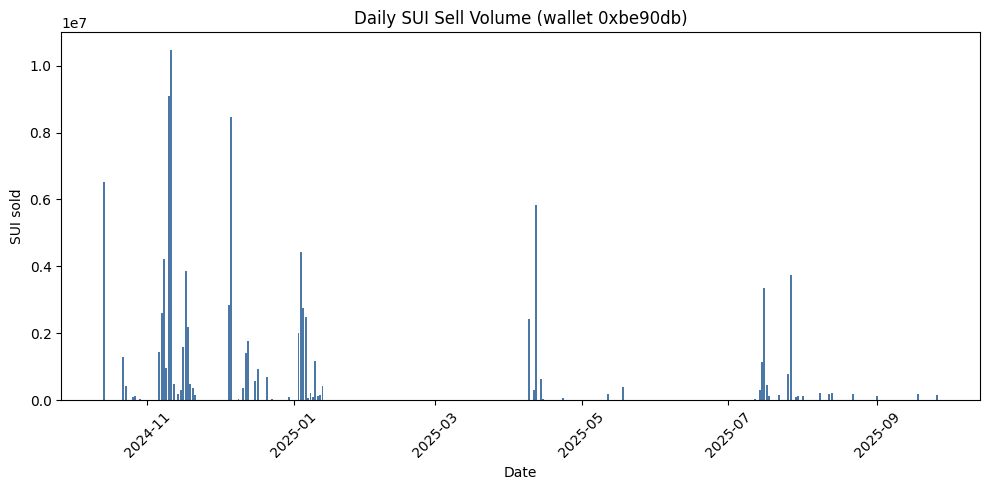

In [143]:
plt.figure(figsize=(10, 5))
plt.bar(daily_sales['timestamp'], daily_sales['daily_sui_sold'], color='#4c78a8')
plt.title('Daily SUI Sell Volume (wallet 0xbe90db)')
plt.ylabel('SUI sold')
plt.xlabel('Date')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


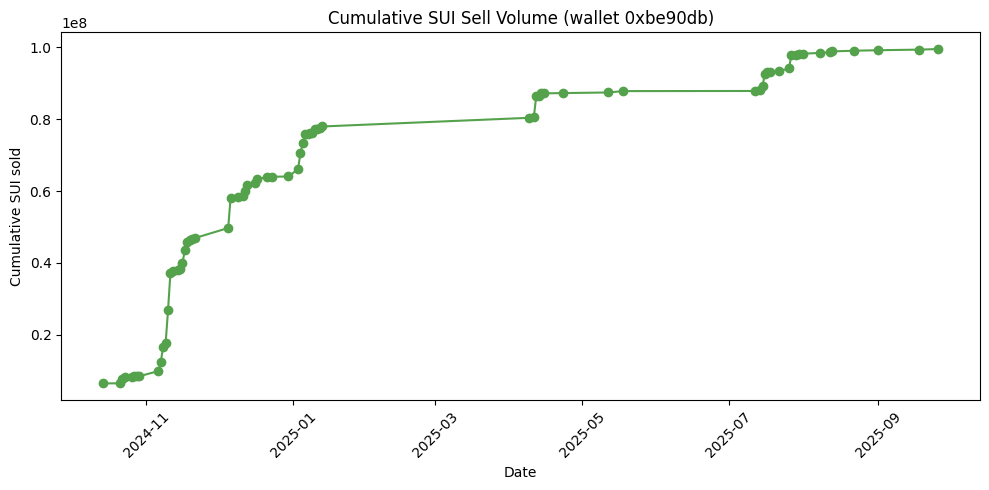

In [144]:
plt.figure(figsize=(10, 5))
plt.plot(daily_sales['timestamp'], daily_sales['cumulative_sui'], color='#54a24b', marker='o')
plt.title('Cumulative SUI Sell Volume (wallet 0xbe90db)')
plt.ylabel('Cumulative SUI sold')
plt.xlabel('Date')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
